<a href="https://colab.research.google.com/github/implementacion-modelos/Implementacion_modelos/blob/modelado/TP_integrador_grupal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importación de librerías

In [ ]:
import kagglehub
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Importación del dataset

In [ ]:
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")
file_path = os.path.join(path, "UCI_Credit_Card.csv")
df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.



## Dimensiones del dataset

In [ ]:
print("Cantidad de columnas: ", len(df.columns))
print("Cantidad de filas: ", len(df))

Cantidad de columnas:  25
Cantidad de filas:  30000


## Glosario de variables

- **ID**: Identificador único de cada cliente.
- **LIMIT_BAL**: Monto del crédito otorgado en dólares taiwaneses (NTD). Incluye créditos individuales y complementarios/familiares.
- **SEX**: Sexo del cliente (1 = Masculino, 2 = Femenino).
- **EDUCATION**: Nivel educativo del cliente (1 = Posgrado, 2 = Universidad, 3 = Secundario, 4 = Otros, 5 = Desconocido, 6 = Desconocido).
- **MARRIAGE**: Estado civil del cliente (1 = Casado/a, 2 = Soltero/a, 3 = Otros).
- **AGE**: Edad del cliente expresada en años.
- **PAY_0**: Estado de pago de septiembre de 2005 (-1 = Pago al día, 1 = 1 mes de atraso, 2 = 2 meses de atraso, …, 8 = 8 meses de atraso, 9 = 9 meses o más de atraso).
- **PAY_2**: Estado de pago de agosto de 2005 (misma escala que PAY_0).
- **PAY_3**: Estado de pago de julio de 2005 (misma escala que PAY_0).
- **PAY_4**: Estado de pago de junio de 2005 (misma escala que PAY_0).
- **PAY_5**: Estado de pago de mayo de 2005 (misma escala que PAY_0).
- **PAY_6**: Estado de pago de abril de 2005 (misma escala que PAY_0).
- **BILL_AMT1**: Monto del resumen de cuenta de septiembre de 2005 (NTD).
- **BILL_AMT2**: Monto del resumen de cuenta de agosto de 2005 (NTD).
- **BILL_AMT3**: Monto del resumen de cuenta de julio de 2005 (NTD).
- **BILL_AMT4**: Monto del resumen de cuenta de junio de 2005 (NTD).
- **BILL_AMT5**: Monto del resumen de cuenta de mayo de 2005 (NTD).
- **BILL_AMT6**: Monto del resumen de cuenta de abril de 2005 (NTD).
- **PAY_AMT1**: Monto del pago realizado en septiembre de 2005 (NTD).
- **PAY_AMT2**: Monto del pago realizado en agosto de 2005 (NTD).
- **PAY_AMT3**: Monto del pago realizado en julio de 2005 (NTD).
- **PAY_AMT4**: Monto del pago realizado en junio de 2005 (NTD).
- **PAY_AMT5**: Monto del pago realizado en mayo de 2005 (NTD).
- **PAY_AMT6**: Monto del pago realizado en abril de 2005 (NTD).
- **default.payment.next.month**: Incumplimiento de pago en el mes siguiente (1 = Sí, 0 = No).

# Revisión de calidad de datos

In [ ]:
print("Tipo de datos que aloja cada columna: ")
print(df.dtypes)

Tipo de datos que aloja cada columna: 
ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: obje

In [ ]:
resumen = pd.DataFrame({
    'tipo_dato': df.dtypes.astype(str),
    'registros': df.count() + df.isna().sum(),
    'vacios': df.isna().sum(),
    'unicos': df.nunique(),
    'duplicados': df.duplicated().sum()
})

resumen['%_vacios'] = (resumen['vacios'] / len(df) * 100).round(2)

display(resumen)

,tipo_dato,registros,vacios,unicos,duplicados,%_vacios
ID,int64,30000,0,30000,0,0.0
LIMIT_BAL,float64,30000,0,81,0,0.0
SEX,int64,30000,0,2,0,0.0
EDUCATION,int64,30000,0,7,0,0.0
MARRIAGE,int64,30000,0,4,0,0.0
AGE,int64,30000,0,56,0,0.0
PAY_0,int64,30000,0,11,0,0.0
PAY_2,int64,30000,0,11,0,0.0
PAY_3,int64,30000,0,11,0,0.0
PAY_4,int64,30000,0,11,0,0.0


## Modificación del nombre de los campos

In [ ]:
df.columns = df.columns.str.lower()
df = df.rename(columns={'default.payment.next.month':'default_pay_next_month'})

## Modificación de tipo de dato y reemplazo de valores

In [ ]:
df['default_pay_next_month'] = df['default_pay_next_month'].astype('str')

df['sex'] = df['sex'].replace({1:'male',2:'female'})
df['marriage'] = df['marriage'].replace({1:'married',2:'single',3:'other',0:'other'})
df['education'] = df['education'].replace({1:'graduate school',2:'university',3:'high school',4:'others',5:'others',6:'others',0:'others'})

columnas_pay = ['pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6']

mapa_pay = {
    -2: 'sin atraso',
    -1: 'sin atraso',
     0: 'sin atraso',
     1: '1 mes de atraso',
     2: '2 meses de atraso',
     3: '3 meses de atraso',
     4: '4 meses de atraso',
     5: '5 meses de atraso',
     6: '6 meses de atraso',
     7: '7 meses de atraso',
     8: '8 meses de atraso',
     9: '9 meses o mas de atraso'
}

df[columnas_pay] = df[columnas_pay].replace(mapa_pay)

df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 30, 40, 50, 60, 70, 80, 90, 100],
    labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90-100']
)

# Análisis exploratorio

## Anáisis univariado

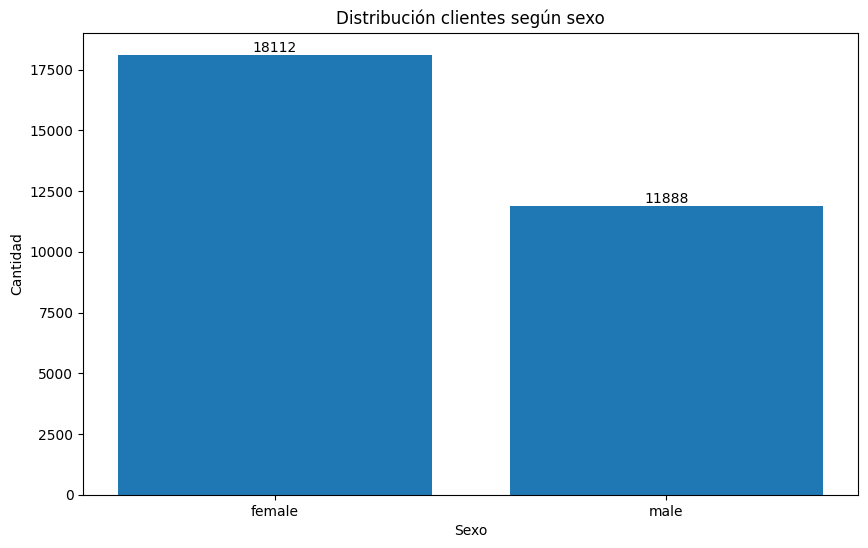

In [ ]:
sex_dist = df['sex'].value_counts()

plt.figure(figsize=(10,6))
bars = plt.bar(sex_dist.index, sex_dist.values)
plt.bar_label(bars)
plt.xlabel('Sexo')
plt.ylabel('Cantidad')
plt.title('Distribución clientes según sexo')
plt.show()

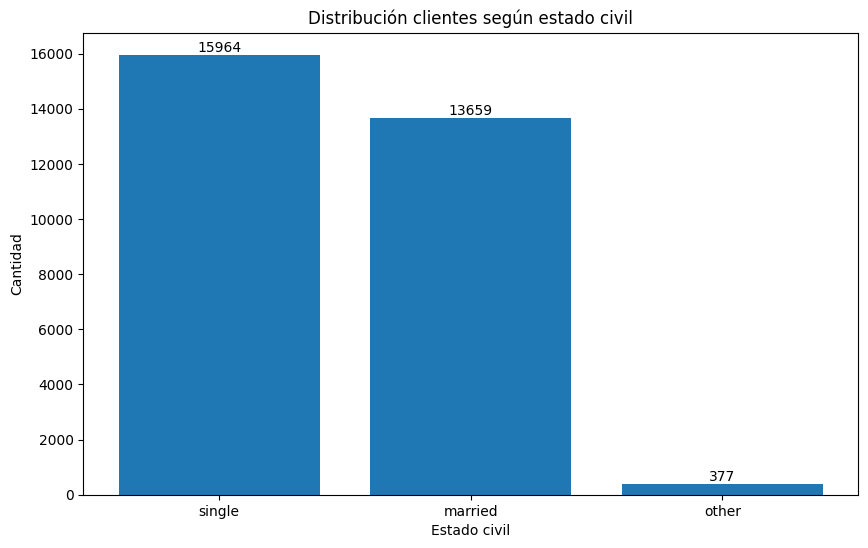

In [ ]:
marriage_dist = df['marriage'].value_counts()

plt.figure(figsize=(10,6))
bars = plt.bar(marriage_dist.index, marriage_dist.values)
plt.bar_label(bars)
plt.xlabel('Estado civil')
plt.ylabel('Cantidad')
plt.title('Distribución clientes según estado civil')
plt.show()

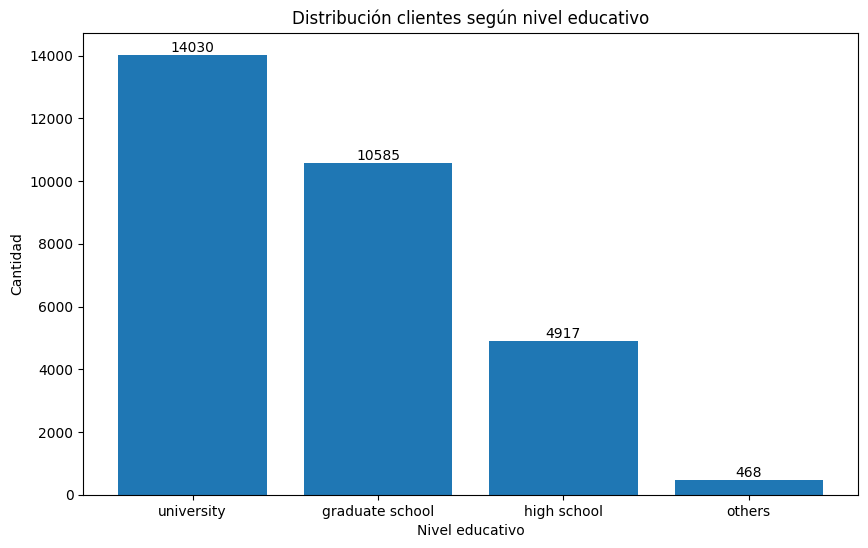

In [ ]:
education_dist = df['education'].value_counts()

plt.figure(figsize=(10,6))
bars = plt.bar(education_dist.index, education_dist.values)
plt.bar_label(bars)
plt.xlabel('Nivel educativo')
plt.ylabel('Cantidad')
plt.title('Distribución clientes según nivel educativo')
plt.show()

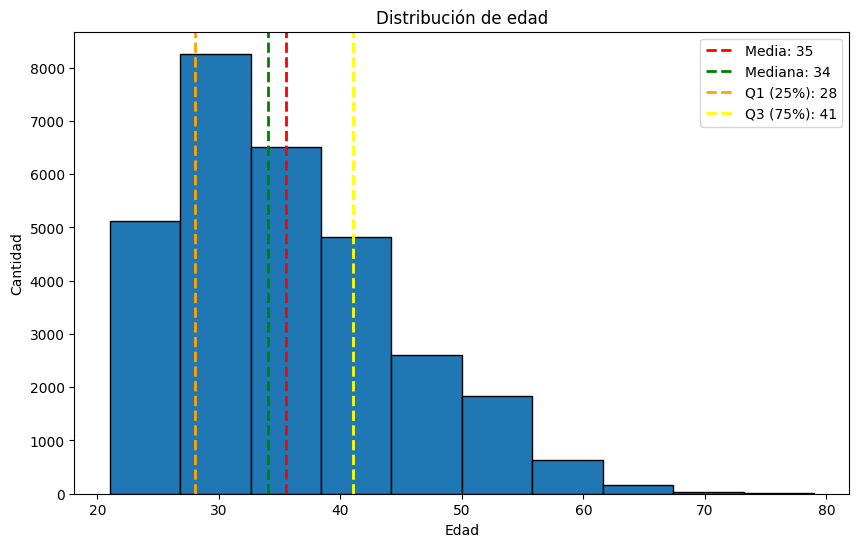

In [ ]:
mean = df['age'].mean()
median = df['age'].median()
q1 = df['age'].quantile(0.25)
q3 = df['age'].quantile(0.75)

plt.figure(figsize=(10,6))
plt.hist(df['age'],bins=10,edgecolor='black')
plt.axvline(mean, color='red', linestyle='dashed', linewidth=2, label=f'Media: {mean:.0f}')
plt.axvline(median, color='green', linestyle='dashed', linewidth=2, label=f'Mediana: {median:.0f}')
plt.axvline(q1, color='orange', linestyle='dashed', linewidth=2, label=f'Q1 (25%): {q1:.0f}')
plt.axvline(q3, color='yellow', linestyle='dashed', linewidth=2, label=f'Q3 (75%): {q3:.0f}')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.title('Distribución de edad')
plt.legend()
plt.show()

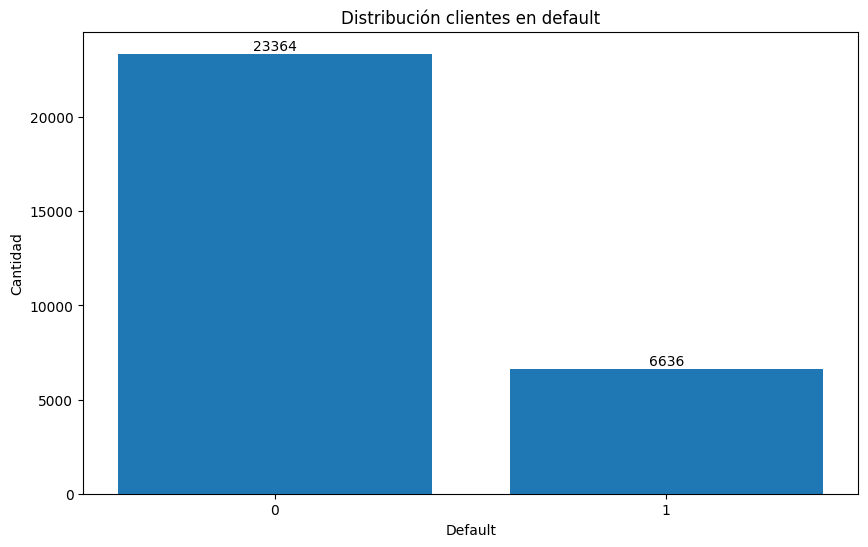

In [ ]:
default_dist = df['default_pay_next_month'].value_counts()

plt.figure(figsize=(10,6))
bars = plt.bar(default_dist.index, default_dist.values)
plt.bar_label(bars)
plt.xlabel('Default')
plt.ylabel('Cantidad')
plt.title('Distribución clientes en default')
plt.show()

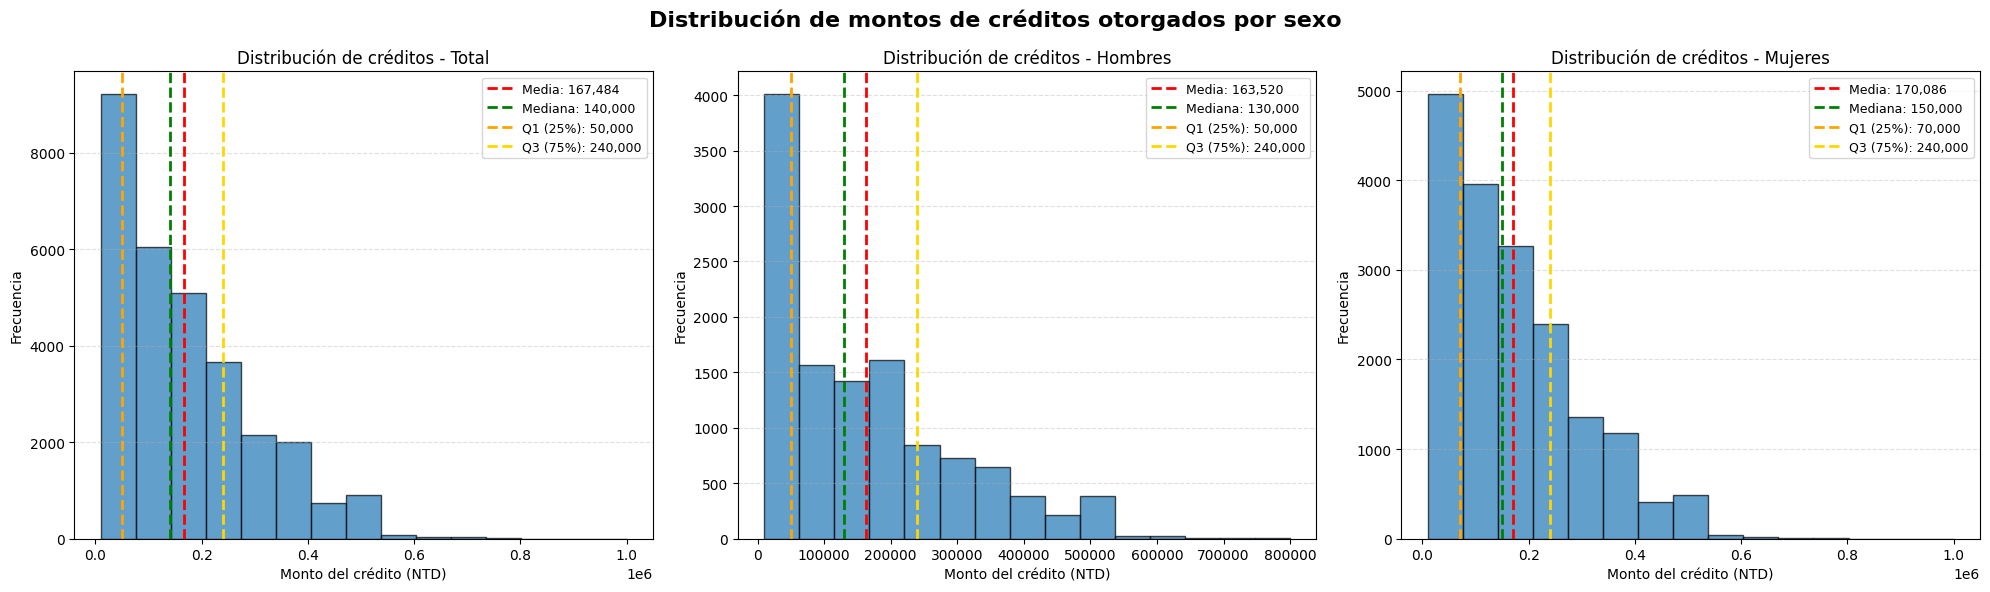

In [ ]:
poblaciones = {
    'Total': df,
    'Hombres': df[df['sex'] == 'male'],
    'Mujeres': df[df['sex'] == 'female']
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for (nombre, datos), ax in zip(poblaciones.items(), axes):

    valores = datos['limit_bal'].dropna()
    mean = valores.mean()
    median = valores.median()
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    ax.hist(valores, bins=15, edgecolor='black', alpha=0.7)
    ax.axvline(mean, color='red', linestyle='dashed',
               linewidth=2, label=f'Media: {mean:,.0f}')
    ax.axvline(median, color='green', linestyle='dashed',
               linewidth=2, label=f'Mediana: {median:,.0f}')
    ax.axvline(q1, color='orange', linestyle='dashed',
               linewidth=2, label=f'Q1 (25%): {q1:,.0f}')
    ax.axvline(q3, color='gold', linestyle='dashed',
               linewidth=2, label=f'Q3 (75%): {q3:,.0f}')
    ax.set_title(f'Distribución de créditos - {nombre}')
    ax.set_xlabel('Monto del crédito (NTD)')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(fontsize=9)

plt.suptitle(
    'Distribución de montos de créditos otorgados por sexo',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

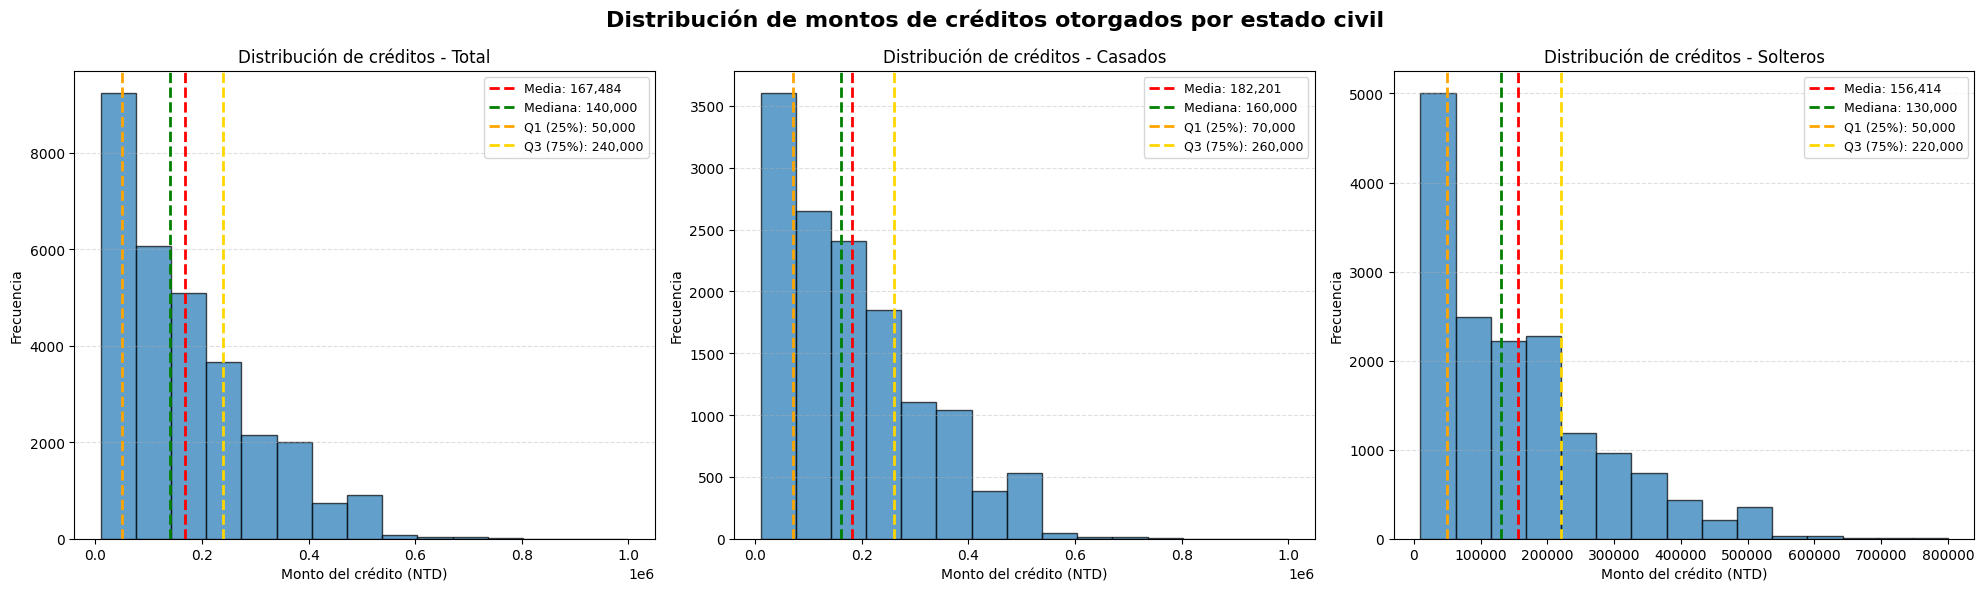

In [ ]:
poblaciones = {
    'Total': df,
    'Casados': df[df['marriage'] == 'married'],
    'Solteros': df[df['marriage'] == 'single']
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for (nombre, datos), ax in zip(poblaciones.items(), axes):

    valores = datos['limit_bal'].dropna()
    mean = valores.mean()
    median = valores.median()
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    ax.hist(valores, bins=15, edgecolor='black', alpha=0.7)
    ax.axvline(mean, color='red', linestyle='dashed',
               linewidth=2, label=f'Media: {mean:,.0f}')
    ax.axvline(median, color='green', linestyle='dashed',
               linewidth=2, label=f'Mediana: {median:,.0f}')
    ax.axvline(q1, color='orange', linestyle='dashed',
               linewidth=2, label=f'Q1 (25%): {q1:,.0f}')
    ax.axvline(q3, color='gold', linestyle='dashed',
               linewidth=2, label=f'Q3 (75%): {q3:,.0f}')
    ax.set_title(f'Distribución de créditos - {nombre}')
    ax.set_xlabel('Monto del crédito (NTD)')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(fontsize=9)

plt.suptitle(
    'Distribución de montos de créditos otorgados por estado civil',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

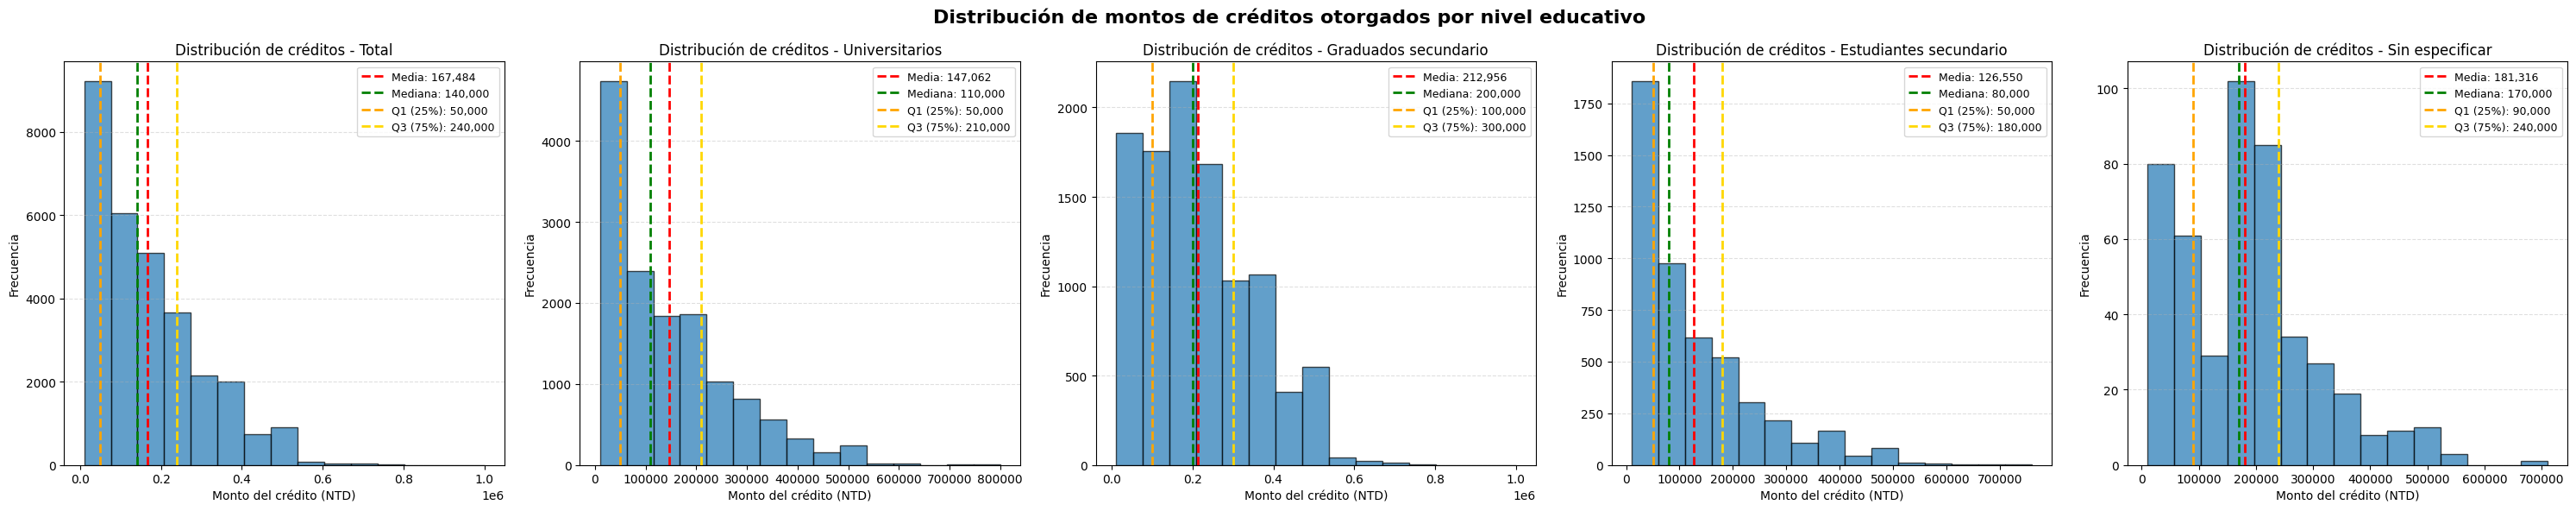

In [ ]:
poblaciones = {
    'Total': df,
    'Universitarios': df[df['education'] == 'university'],
    'Graduados secundario': df[df['education'] == 'graduate school'],
    'Estudiantes secundario': df[df['education'] == 'high school'],
    'Sin especificar': df[df['education'] == 'others'],
}

fig, axes = plt.subplots(1, 5, figsize=(30, 6))

for (nombre, datos), ax in zip(poblaciones.items(), axes):

    valores = datos['limit_bal'].dropna()
    mean = valores.mean()
    median = valores.median()
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    ax.hist(valores, bins=15, edgecolor='black', alpha=0.7)
    ax.axvline(mean, color='red', linestyle='dashed',
               linewidth=2, label=f'Media: {mean:,.0f}')
    ax.axvline(median, color='green', linestyle='dashed',
               linewidth=2, label=f'Mediana: {median:,.0f}')
    ax.axvline(q1, color='orange', linestyle='dashed',
               linewidth=2, label=f'Q1 (25%): {q1:,.0f}')
    ax.axvline(q3, color='gold', linestyle='dashed',
               linewidth=2, label=f'Q3 (75%): {q3:,.0f}')
    ax.set_title(f'Distribución de créditos - {nombre}')
    ax.set_xlabel('Monto del crédito (NTD)')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(fontsize=9)

plt.suptitle(
    'Distribución de montos de créditos otorgados por nivel educativo',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

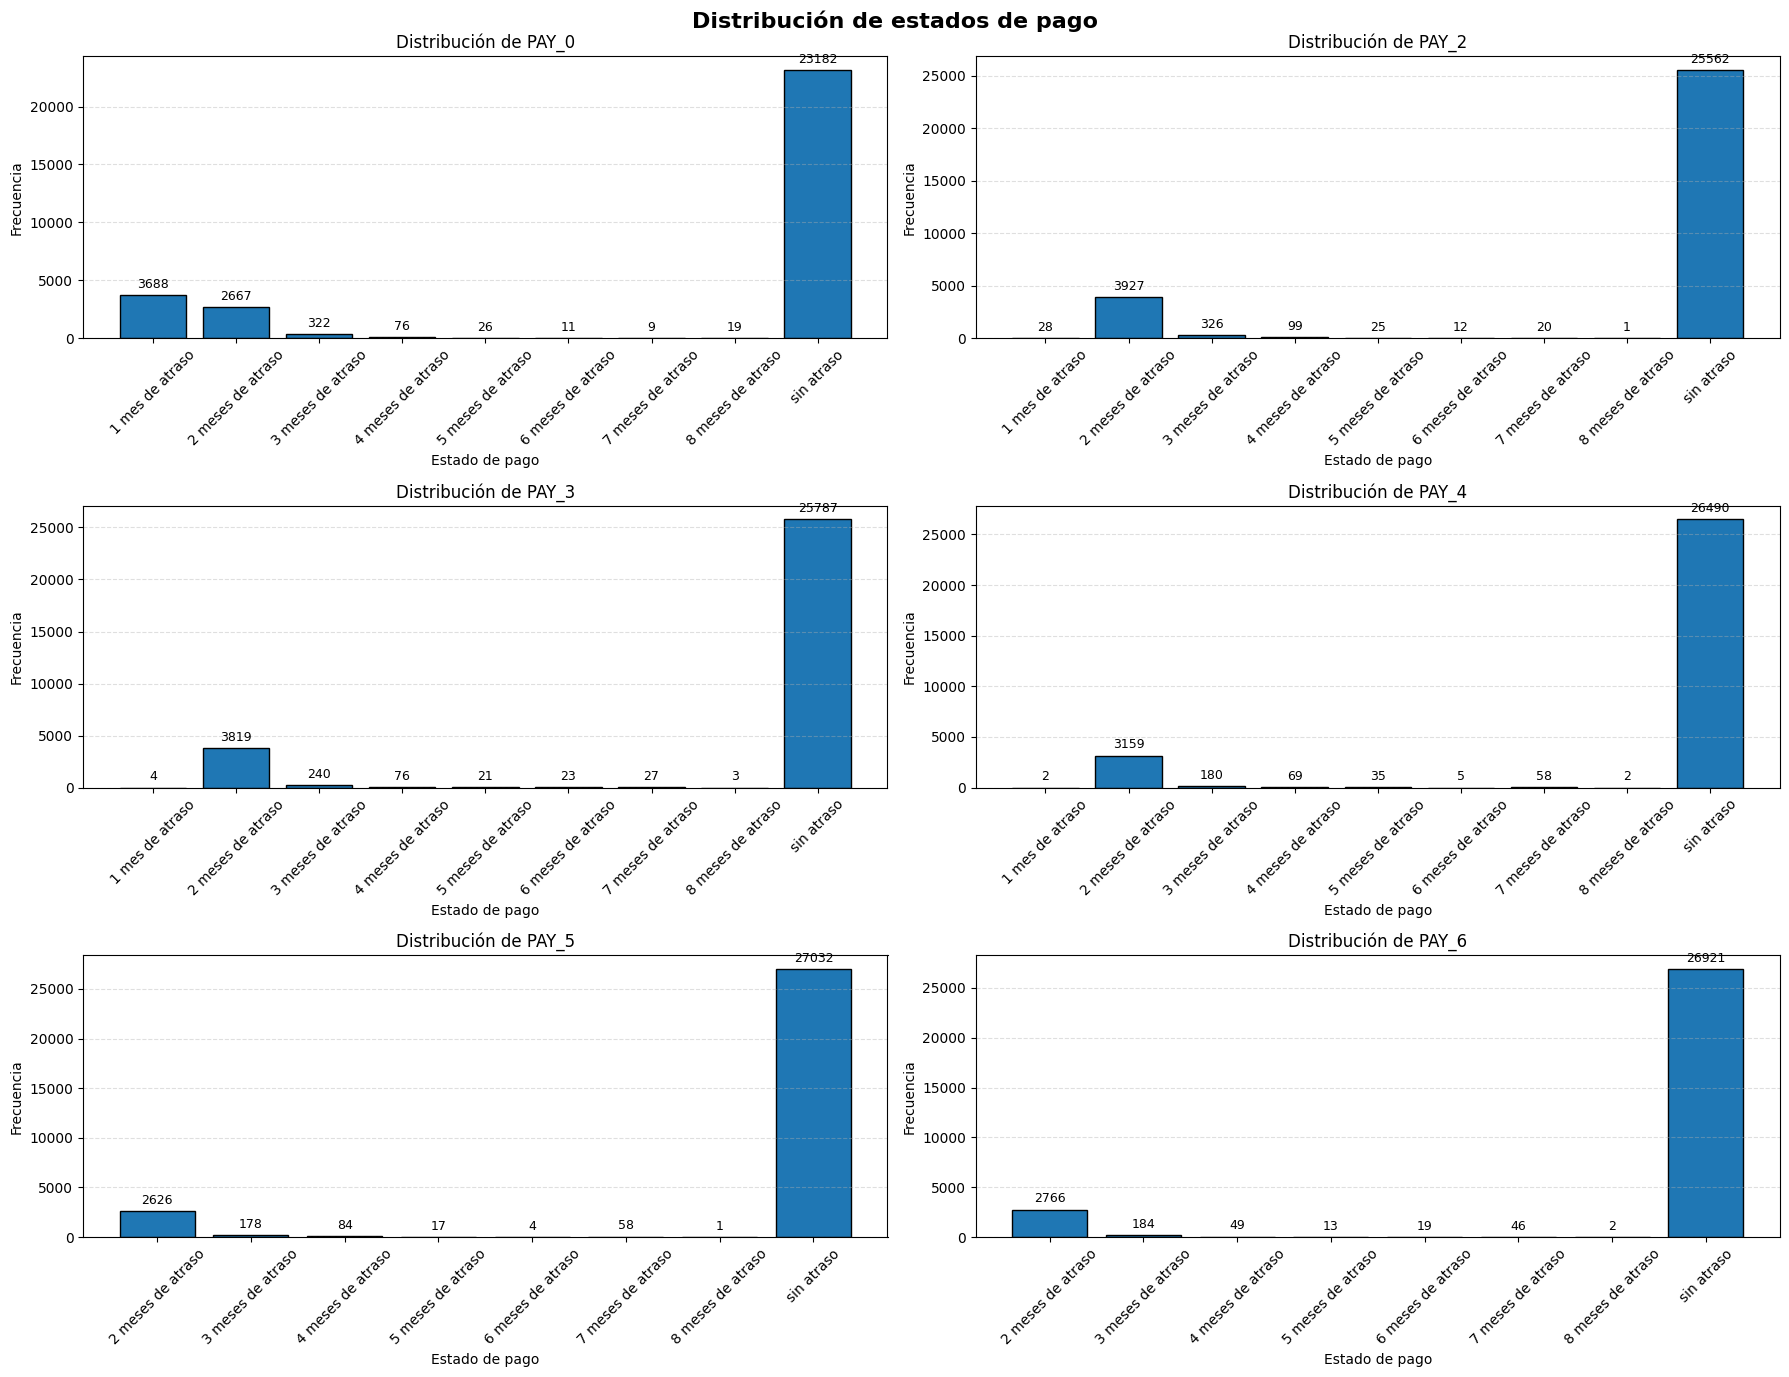

In [ ]:
columnas_pay = ['pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6']

fig, axes = plt.subplots(3, 2, figsize=(18, 14))

for col, ax in zip(columnas_pay, axes.flatten()):

    valores = df[col].value_counts(dropna=False).sort_index()

    ax.bar(valores.index.astype(str), valores.values, edgecolor='black')

    ax.set_title(f'Distribución de {col.upper()}')
    ax.set_xlabel('Estado de pago')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.tick_params(axis='x', rotation=45)

    # Etiquetas de frecuencia sobre las barras
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)

plt.suptitle('Distribución de estados de pago', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

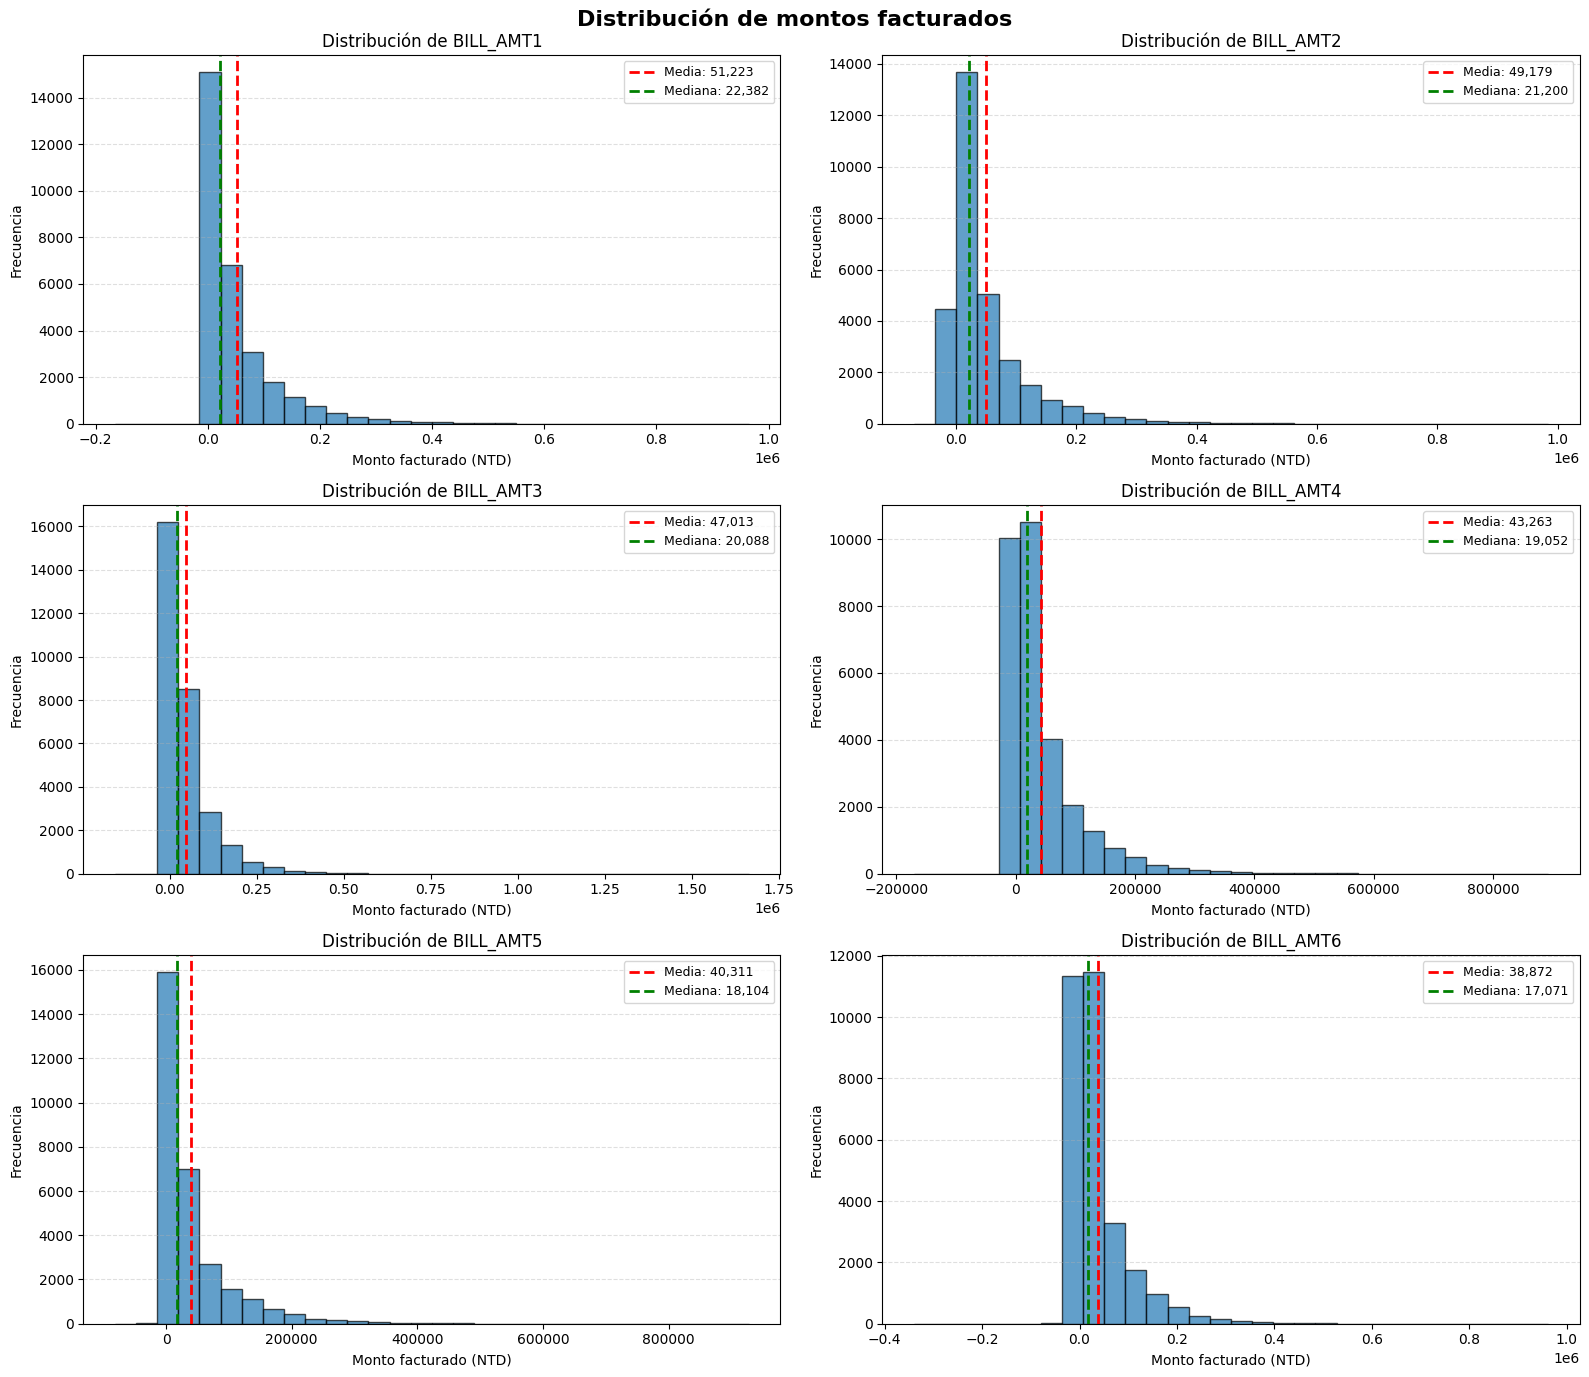

In [ ]:
columnas_bill = [
    'bill_amt1', 'bill_amt2', 'bill_amt3',
    'bill_amt4', 'bill_amt5', 'bill_amt6'
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for col, ax in zip(columnas_bill, axes.flatten()):

    valores = df[col].dropna()

    mean = valores.mean()
    median = valores.median()

    ax.hist(valores, bins=30, edgecolor='black', alpha=0.7)

    ax.axvline(mean, color='red', linestyle='dashed',
               linewidth=2, label=f'Media: {mean:,.0f}')

    ax.axvline(median, color='green', linestyle='dashed',
               linewidth=2, label=f'Mediana: {median:,.0f}')

    ax.set_title(f'Distribución de {col.upper()}')
    ax.set_xlabel('Monto facturado (NTD)')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(fontsize=9)

plt.suptitle(
    'Distribución de montos facturados',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

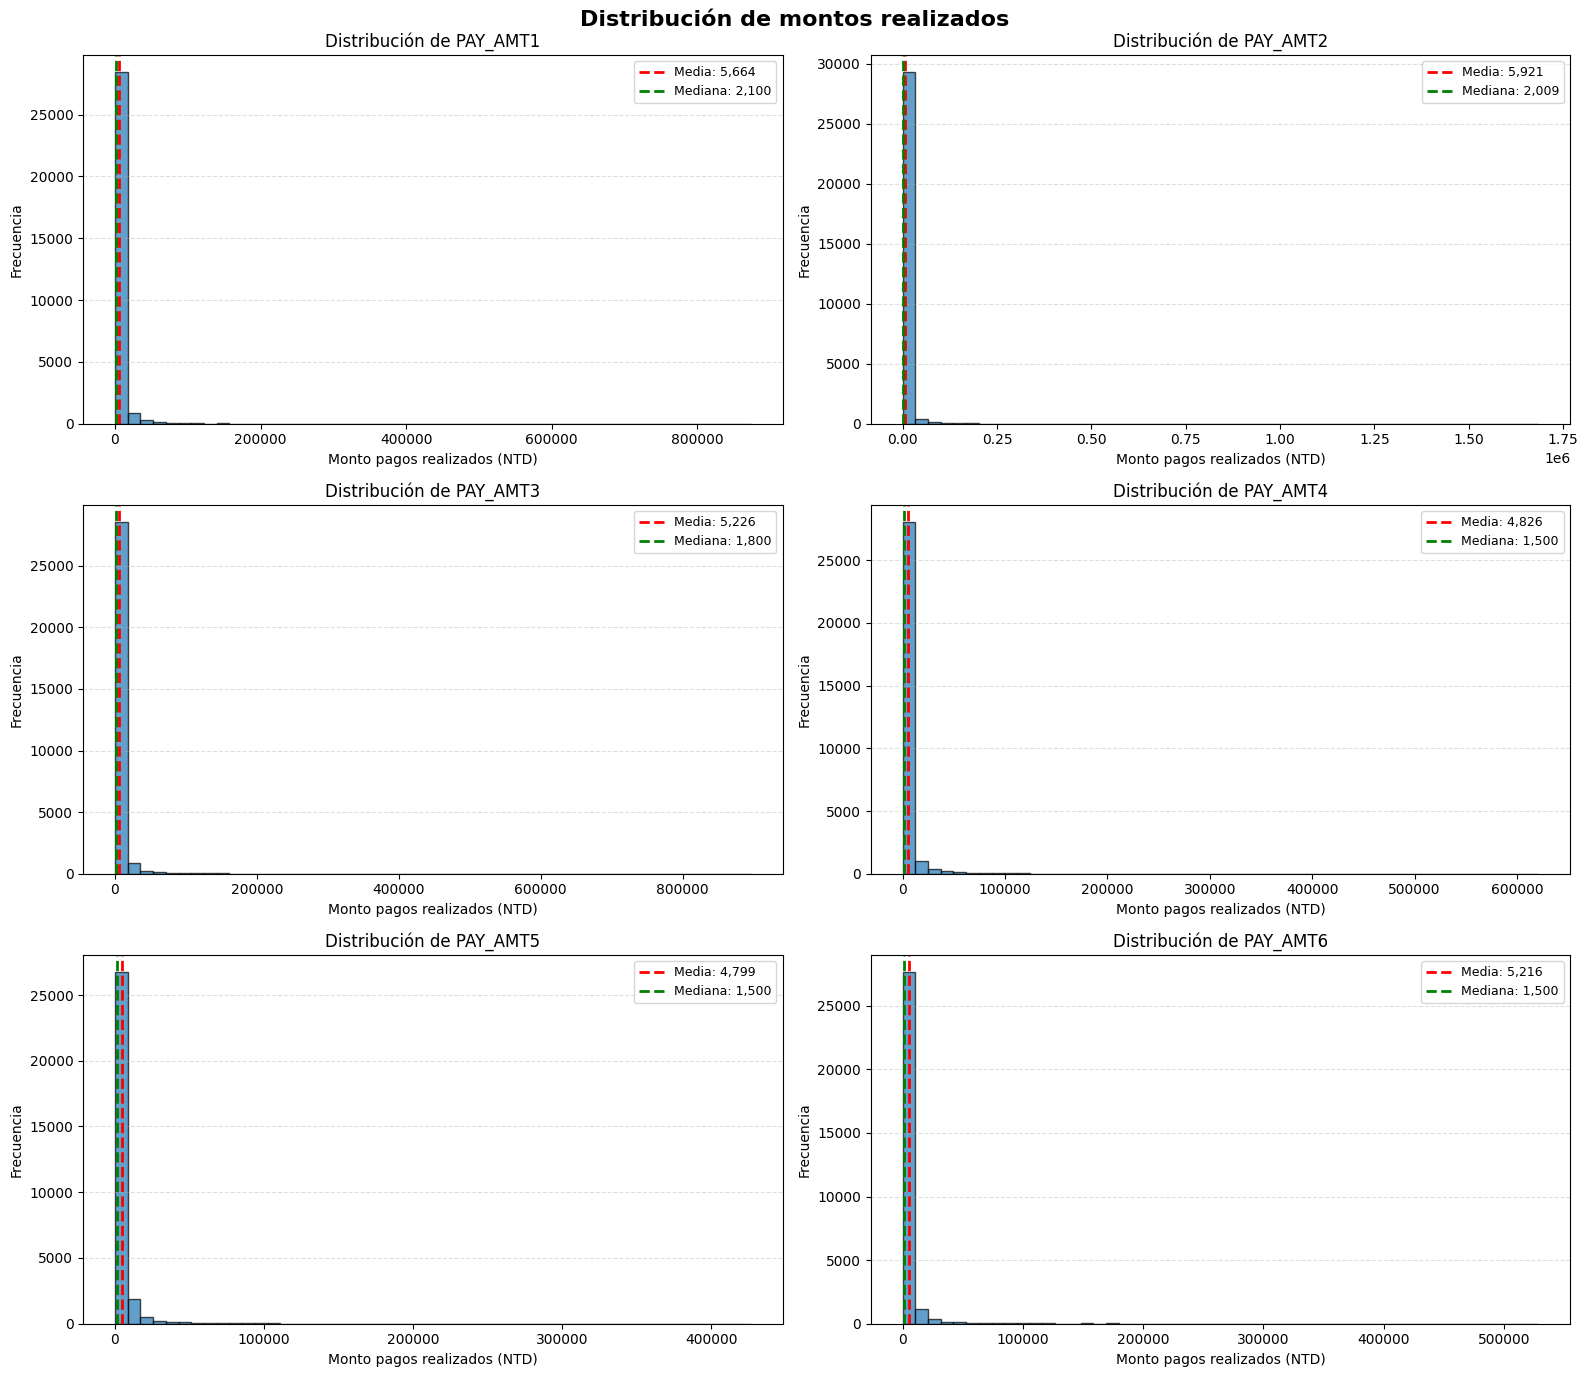

In [ ]:
columnas_bill = [
    'pay_amt1', 'pay_amt2', 'pay_amt3',
    'pay_amt4', 'pay_amt5', 'pay_amt6'
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for col, ax in zip(columnas_bill, axes.flatten()):

    valores = df[col].dropna()

    mean = valores.mean()
    median = valores.median()

    ax.hist(valores, bins=50, edgecolor='black', alpha=0.7)

    ax.axvline(mean, color='red', linestyle='dashed',
               linewidth=2, label=f'Media: {mean:,.0f}')

    ax.axvline(median, color='green', linestyle='dashed',
               linewidth=2, label=f'Mediana: {median:,.0f}')

    ax.set_title(f'Distribución de {col.upper()}')
    ax.set_xlabel('Monto pagos realizados (NTD)')
    ax.set_ylabel('Frecuencia')
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.legend(fontsize=9)

plt.suptitle(
    'Distribución de montos realizados',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Análisis bivariado

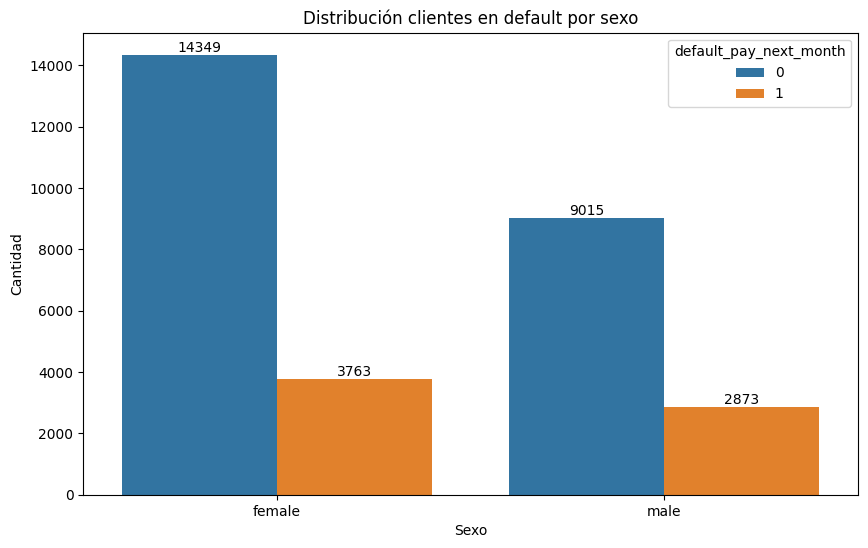

In [ ]:
default_sex_dist = df.groupby(['sex','default_pay_next_month'])['id'].count().reset_index(name='count')

plt.figure(figsize=(10,6))
bar = sns.barplot(data=default_sex_dist, x='sex', y='count', hue='default_pay_next_month')
plt.bar_label(bar.containers[0])
plt.bar_label(bar.containers[1])
plt.xlabel('Sexo')
plt.ylabel('Cantidad')
plt.title('Distribución clientes en default por sexo')
plt.show()

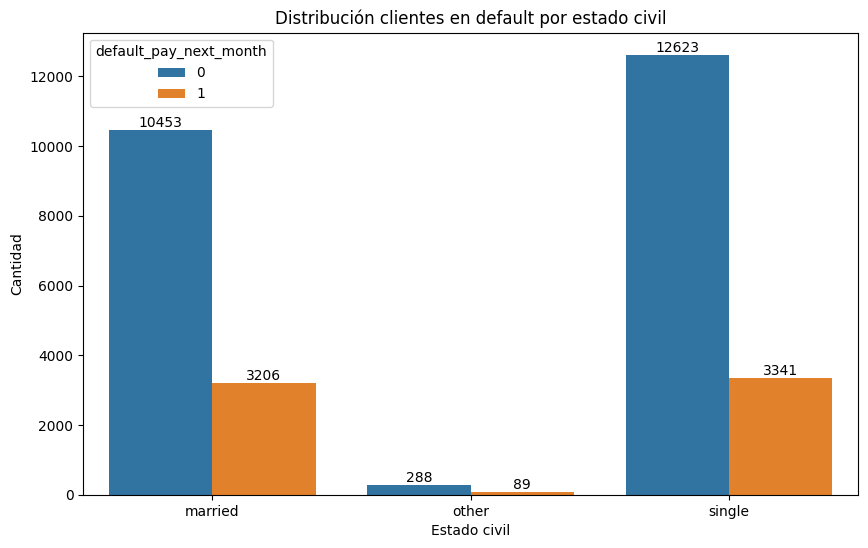

In [ ]:
default_marriage_dist = df.groupby(['marriage','default_pay_next_month'])['id'].count().reset_index(name='count')

plt.figure(figsize=(10,6))
bar = sns.barplot(data=default_marriage_dist, x='marriage', y='count', hue='default_pay_next_month')
plt.bar_label(bar.containers[0])
plt.bar_label(bar.containers[1])
plt.xlabel('Estado civil')
plt.ylabel('Cantidad')
plt.title('Distribución clientes en default por estado civil')
plt.show()

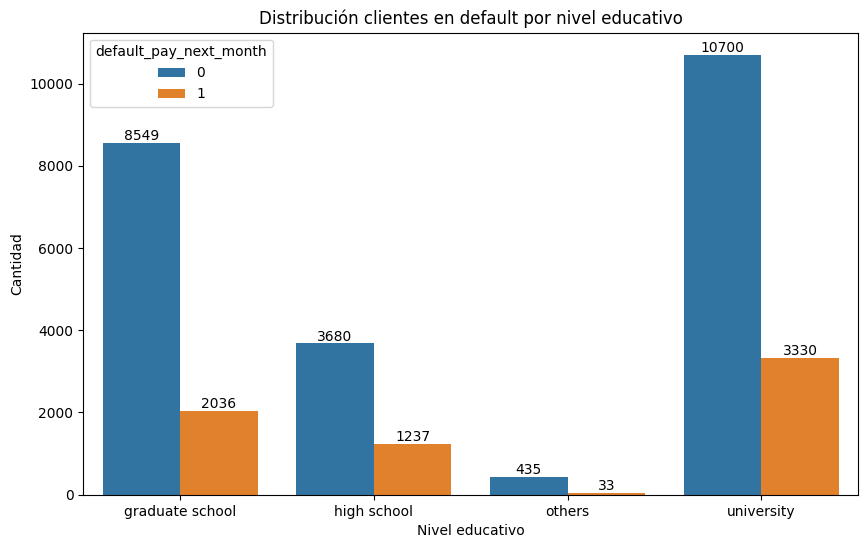

In [ ]:
default_education_dist = df.groupby(['education','default_pay_next_month'])['id'].count().reset_index(name='count')

plt.figure(figsize=(10,6))
bar = sns.barplot(data=default_education_dist, x='education', y='count', hue='default_pay_next_month')
plt.bar_label(bar.containers[0])
plt.bar_label(bar.containers[1])
plt.xlabel('Nivel educativo')
plt.ylabel('Cantidad')
plt.title('Distribución clientes en default por nivel educativo')
plt.show()

/tmp/ipykernel_2392/3114924785.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_age_dist = df.groupby(['age_group','default_pay_next_month'])['id'].count().reset_index(name='count')


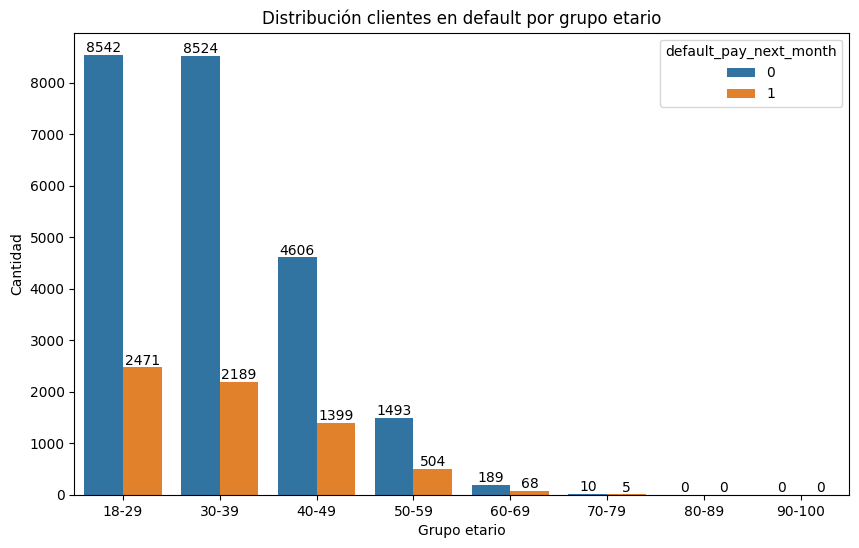

In [ ]:
default_age_dist = df.groupby(['age_group','default_pay_next_month'])['id'].count().reset_index(name='count')

plt.figure(figsize=(10,6))
bar = sns.barplot(data=default_age_dist, x='age_group', y='count', hue='default_pay_next_month')
plt.bar_label(bar.containers[0])
plt.bar_label(bar.containers[1])
plt.xlabel('Grupo etario')
plt.ylabel('Cantidad')
plt.title('Distribución clientes en default por grupo etario')
plt.show()

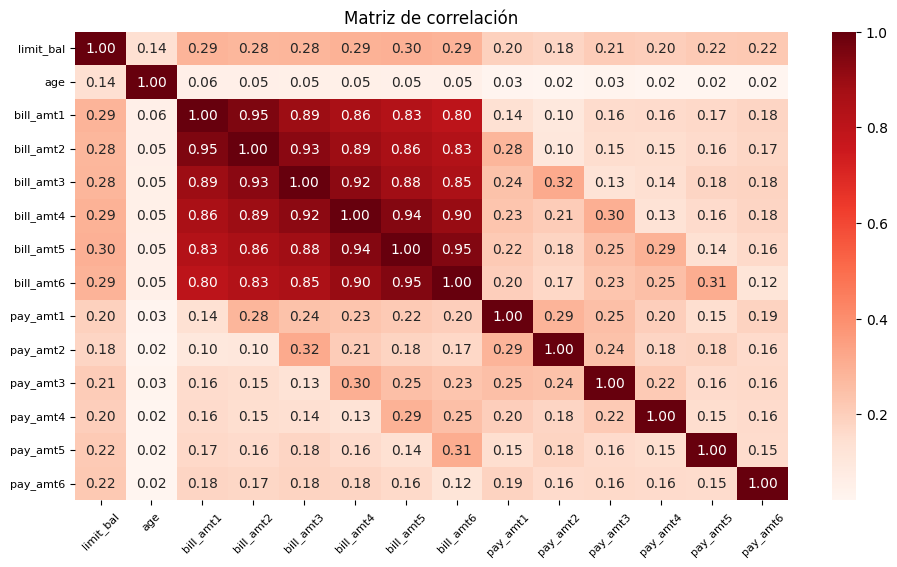

In [ ]:
df_num = df.select_dtypes(include=["int", "float"])
df_num = df_num.drop(columns='id')

correlacion = df_num.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(
    correlacion,
    annot=True,
    cmap="Reds",
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.tight_layout()
plt.xticks(fontsize=8, rotation = 45)
plt.yticks(fontsize=8)
plt.show()

# **Importación para Split, predictores, preprocesamiento**

In [ ]:
#Librerias y Definición de Semilla
import kagglehub
import os
import pandas as pd
import numpy as np


from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Semilla única para que todas las separaciones aleatorias sean reproducibles
SEED = 42

#Para el empaquetado
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer


In [ ]:
path = kagglehub.dataset_download(
    "uciml/default-of-credit-card-clients-dataset")

file_path = os.path.join(path, "UCI_Credit_Card.csv")

df_model = pd.read_csv(file_path)

df_model.columns = df_model.columns.str.lower()

df_model = df_model.rename(columns={
    "default.payment.next.month": "default_pay_next_month",
    "pay_0": "pay_1"
})

# Copia de trabajo para modelado
df_2 = df_model.copy()

TARGET = "default_pay_next_month"

# Target numérico 0/1
df_2[TARGET] = df_2[TARGET].astype(int)

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.


Limpieza Previa a la separación Split / Test / Producción

In [ ]:
# Eliminación de duplicados considerando todas las columnas salvo ID
cols_sin_id = [c for c in df_2.columns if c != "id"]

print(
    "Duplicados (sin ID):",
    df_2.duplicated(subset=cols_sin_id).sum()
)

df_2 = (
    df_2
    .drop_duplicates(subset=cols_sin_id)
    .reset_index(drop=True)
)

# Controles finales
assert df_2[TARGET].isna().sum() == 0

print("Dimensión final:", df_2.shape)
print(f"Tasa de default: {df_2[TARGET].mean():.2%}")

Duplicados (sin ID): 35
Dimensión final: (29965, 25)
Tasa de default: 22.13%


In [ ]:
def print_stats(df_2: pd.DataFrame):
    print("Estadísticas descriptivas:")
    display(df_2.describe(include="all").T)



print_stats(df_2)

Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
id,29965.0,14994.932521,8659.328323,1.0,7497.0,14992.0,22494.0,30000.0
limit_bal,29965.0,167442.005006,129760.135222,10000.0,50000.0,140000.0,240000.0,1000000.0
sex,29965.0,1.603738,0.489128,1.0,1.0,2.0,2.0,2.0
education,29965.0,1.853629,0.790411,0.0,1.0,2.0,2.0,6.0
marriage,29965.0,1.551877,0.521997,0.0,1.0,2.0,2.0,3.0
age,29965.0,35.487969,9.219459,21.0,28.0,34.0,41.0,79.0
pay_1,29965.0,-0.016753,1.123492,-2.0,-1.0,0.0,0.0,8.0
pay_2,29965.0,-0.131854,1.196322,-2.0,-1.0,0.0,0.0,8.0
pay_3,29965.0,-0.164392,1.195878,-2.0,-1.0,0.0,0.0,8.0
pay_4,29965.0,-0.218922,1.168175,-2.0,-1.0,0.0,0.0,8.0


##**Split Entrenamiento, Evaluación y lote de Producción**

In [ ]:
# 1) Reservamos 20% para producción
df_modelo, df_prod = train_test_split(
    df_2,
    test_size=0.20,
    stratify=df_2[TARGET],
    random_state=SEED
)

# 2) Del 80% restante, reservamos 25% para evaluación
# 25% de 80% = 20% del dataset original
df_train, df_test = train_test_split(
    df_modelo,
    test_size=0.25,
    stratify=df_modelo[TARGET],
    random_state=SEED
)

# Separamos predictores (X) y objetivo (y)
X_train, y_train = df_train.drop(columns=TARGET), df_train[TARGET]
X_test,  y_test  = df_test.drop(columns=TARGET),  df_test[TARGET]
X_prod,  y_prod  = df_prod.drop(columns=TARGET),  df_prod[TARGET]

# Control: tamaños y tasa de default
resumen_split = pd.DataFrame({
    "registros": [len(y_train), len(y_test), len(y_prod)],
    "tasa_default": [
        y_train.mean(),
        y_test.mean(),
        y_prod.mean()
    ],
}, index=["entrenamiento", "evaluación", "producción"])

# Usar df_2, ya que es el dataset que realmente estás dividiendo
resumen_split["%_total"] = (
    resumen_split["registros"] / len(df_2)
)

resumen_split.style.format({
    "tasa_default": "{:.2%}",
    "%_total": "{:.1%}"
})

,registros,tasa_default,%_total
entrenamiento,17979,22.13%,60.0%
evaluación,5993,22.13%,20.0%
producción,5993,22.13%,20.0%


In [ ]:
print(f"Total df_2: {len(df_2)}")
print(f"Train: {len(df_train)} ({len(df_train)/len(df_2):.1%})")
print(f"Test:  {len(df_test)} ({len(df_test)/len(df_2):.1%})")
print(f"Prod:  {len(df_prod)} ({len(df_prod)/len(df_2):.1%})")

Total df_2: 29965
Train: 17979 (60.0%)
Test:  5993 (20.0%)
Prod:  5993 (20.0%)


# **Predictores y Preprocesamiento**

A partir de las variables originales se construyeron nuevos predictores para resumir el comportamiento crediticio reciente de cada cliente:

| Predictor | Interpretación |
|---|---|
| `max_atraso` | Máximo atraso registrado durante los últimos 6 meses. |
| `meses_con_atraso` | Cantidad de meses en los que el cliente presentó atraso. |
| `utilizacion_1` | Proporción del límite de crédito utilizada en el último mes. |
| `utilizacion_prom` | Utilización promedio del límite durante los últimos 6 meses. |
| `tasa_pago_prom` | Proporción promedio del saldo facturado que el cliente paga, relacionando cada pago con el saldo del período anterior. |
| `tendencia_deuda` | Variación de la deuda entre abril y septiembre respecto del límite de crédito. |

Adicionalmente:

- Los estados de pago negativos y cero se consideran **sin atraso**, mientras que los valores positivos conservan la cantidad de meses de atraso.
- Los montos monetarios se transforman a **escala logarítmica** para reducir la influencia de distribuciones asimétricas y valores extremos.
- Se aplican límites a algunas variables derivadas y a la edad para reducir la influencia de observaciones extremas.
- La variable `sex` se excluye del modelo principal por considerarse un **atributo protegido** en decisiones de crédito.
- Todos los predictores utilizan únicamente información disponible hasta septiembre para predecir el incumplimiento del mes siguiente, evitando incorporar información futura (*target leakage*).

In [ ]:
# Configuración
# El sexo se considera un atributo protegido.
# Se excluye del modelo principal, aunque puede habilitarse para realizar un análisis comparativo.
INCLUIR_SEXO = False

MESES = range(1, 7)  # 1 = septiembre de 2005; 6 = abril de 2005

COLS_PAY = [f"pay_{i}" for i in MESES]
COLS_BILL = [f"bill_amt{i}" for i in MESES]
COLS_PAY_AMT = [f"pay_amt{i}" for i in MESES]


# Funciones Auxiliares

def signed_log1p(x):
    """
    Aplica log(1 + |x|) conservando el signo.

    Se utiliza para los saldos facturados porque pueden existir
    valores negativos, por ejemplo, saldos a favor del cliente.
    """
    return np.sign(x) * np.log1p(np.abs(x))


def preprocess(X: pd.DataFrame, y=None) -> pd.DataFrame:
    """
    Prepara los predictores para el modelado.

    Incluye:
    - recategorización;
    - tratamiento del historial de atrasos;
    - ingeniería de variables;
    - tratamiento de valores extremos;
    - transformación logarítmica de montos;
    - exclusión del identificador y, opcionalmente, del sexo.

    El parámetro y se incluye por compatibilidad con pipelines,
    aunque no se utiliza en las transformaciones.
    """

    val = X.copy()

    # Validación de columnas necesarias

    columnas_requeridas = (
        ["id", "limit_bal", "age", "education", "marriage", "sex"]
        + COLS_PAY
        + COLS_BILL
        + COLS_PAY_AMT
    )

    columnas_faltantes = [
        columna
        for columna in columnas_requeridas
        if columna not in val.columns
    ]

    if columnas_faltantes:
        raise ValueError(
            "Faltan columnas requeridas para el preprocesamiento: "
            f"{columnas_faltantes}"
        )

    # Recategorización

    # Education:
    # 1 = graduate school
    # 2 = university
    # 3 = high school
    # 0, 4, 5 y 6 se agrupan como others.
    val["education"] = (
        val["education"]
        .map({
            1: "graduate school",
            2: "university",
            3: "high school"
        })
        .fillna("others")
    )

    # Marriage:
    # 1 = married
    # 2 = single
    # 0 y 3 se agrupan como other.
    val["marriage"] = (
        val["marriage"]
        .map({
            1: "married",
            2: "single"
        })
        .fillna("other")
    )

    # Sex:
    # Se conserva como variable categórica únicamente si luego se decide incluirla en el modelo.
    val["sex"] = (
        val["sex"]
        .map({
            1: "male",
            2: "female"
        })
        .fillna("unknown")
    )

    # Historial de pagos
    # Los códigos negativos y cero se recodifican como 0: ausencia de atraso.
    # Los valores positivos representan meses de atraso y conservan su orden.
    val[COLS_PAY] = val[COLS_PAY].clip(lower=0, upper=8)

    # Mayor severidad de atraso en los últimos seis meses.
    val["max_atraso"] = val[COLS_PAY].max(axis=1)

    # Cantidad de meses en los que se registró atraso.
    val["meses_con_atraso"] = (
        val[COLS_PAY].gt(0).sum(axis=1)
    )

    # Utilización del límite de crédito

    # Evita división por cero o por límites negativos.
    limite = val["limit_bal"].clip(lower=1)

    # Utilización del último mes disponible
    val["utilizacion_1"] = (
        val["bill_amt1"] / limite
    ).clip(lower=-1, upper=3)

    # Utilización promedio
    val["utilizacion_prom"] = (
        val[COLS_BILL].mean(axis=1) / limite
    ).clip(lower=-1, upper=3)

    # Comportamiento de pago
    ratios_pago = []

    # PAY_AMT1 corresponde al pago realizado en septiembre
    # sobre el saldo facturado del mes anterior, BILL_AMT2.
    #
    # Se construyen cinco relaciones:
    # PAY_AMT1 / BILL_AMT2
    # PAY_AMT2 / BILL_AMT3
    # ...
    # PAY_AMT5 / BILL_AMT6
    for i in range(1, 6):

        pago = val[f"pay_amt{i}"]
        saldo_anterior = val[f"bill_amt{i + 1}"]

        # Por defecto, si no existía saldo positivo, el ratio se fija en 1
        ratio = pd.Series(
            1.0,
            index=val.index,
            dtype="float64"
        )

        tiene_saldo = saldo_anterior > 0

        ratio.loc[tiene_saldo] = (
            pago.loc[tiene_saldo]
            / saldo_anterior.loc[tiene_saldo]
        )

        # Evita ratios negativos y limita pagos muy superiores al saldo facturado.
        ratio = ratio.clip(lower=0, upper=1.5)

        ratios_pago.append(ratio)

    # Promedio por cliente de las cinco relaciones mensuales.
    val["tasa_pago_prom"] = pd.concat(
        ratios_pago,
        axis=1
    ).mean(axis=1)

    # Tendencia de la deuda
    # Variación entre septiembre y abril, relativizada por el límite de crédito.
    #
    # Valor positivo: la deuda aumentó.
    # Valor negativo: la deuda disminuyó.
    val["tendencia_deuda"] = (
        (val["bill_amt1"] - val["bill_amt6"]) / limite
    ).clip(lower=-3, upper=3)

    # Transformaciones logarítmicas
    # El límite de crédito no debería ser negativo.
    val["log_limit_bal"] = np.log1p(
        val["limit_bal"].clip(lower=0)
    )

    # Los saldos pueden ser negativos, por lo que conservamos el signo después de la transformación.
    for columna in COLS_BILL:
        val[f"log_{columna}"] = signed_log1p(
            val[columna]
        )

    # Los pagos se restringen a valores no negativos.
    for columna in COLS_PAY_AMT:
        val[f"log_{columna}"] = np.log1p(
            val[columna].clip(lower=0)
        )

    # Tratamiento de la edad
    # Se acotan los extremos poco poblados para evitar que afecten de forma desproporcionada el escalado.
    val["age"] = val["age"].clip(lower=21, upper=70)

    # Eliminación de variables reemplazadas
    columnas_eliminar = (
        ["id", "limit_bal"]
        + COLS_BILL
        + COLS_PAY_AMT
    )

    val = val.drop(
        columns=columnas_eliminar,
        errors="ignore"
    )

    # Por decisión del grupo, el sexo no forma parte del modelo principal.
    if not INCLUIR_SEXO:
        val = val.drop(
            columns=["sex"],
            errors="ignore"
        )

    return val

In [ ]:
#Check

preview = preprocess(X_train)

print("Dimensión original de X_train:", X_train.shape)
print("Dimensión después del preprocesamiento:", preview.shape)
print("Faltantes después del preprocesamiento:", preview.isna().sum().sum())

display(preview.head())

Dimensión original de X_train: (17979, 24)
Dimensión después del preprocesamiento: (17979, 28)
Faltantes después del preprocesamiento: 0


,education,marriage,age,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6,max_atraso,...,log_bill_amt3,log_bill_amt4,log_bill_amt5,log_bill_amt6,log_pay_amt1,log_pay_amt2,log_pay_amt3,log_pay_amt4,log_pay_amt5,log_pay_amt6
3336,university,single,24,0,0,0,2,0,0,2,...,10.494159,10.288240,10.287286,10.278150,8.216358,8.593599,1.945910,6.911747,7.279319,6.930495
14434,graduate school,single,28,0,0,0,0,0,0,0,...,7.871311,7.637234,8.462315,7.031741,9.031094,7.871311,7.639161,8.462315,7.031741,7.656810
3233,university,married,33,1,0,0,0,0,0,1,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9945,university,single,24,0,0,0,0,0,0,0,...,-3.332205,8.602269,-2.639057,-2.639057,9.387984,0.000000,8.607217,0.000000,0.000000,0.000000
6164,graduate school,married,33,1,0,0,0,0,0,1,...,-4.709530,-5.739793,11.322866,11.344862,2.302585,0.000000,0.000000,11.326608,8.006701,8.425516


In [ ]:
#Estadisticas nuevas variables

columnas_derivadas = [
    "max_atraso",
    "meses_con_atraso",
    "utilizacion_1",
    "utilizacion_prom",
    "tasa_pago_prom",
    "tendencia_deuda"
]

display(
    preview[columnas_derivadas]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
max_atraso,17979.0,0.687636,1.081138,0.000000,0.000000,0.000000,2.000000,8.0
meses_con_atraso,17979.0,0.837310,1.555069,0.000000,0.000000,0.000000,1.000000,6.0
utilizacion_1,17979.0,0.426779,0.409776,-0.619892,0.021831,0.320829,0.838318,3.0
utilizacion_prom,17979.0,0.376260,0.352405,-0.200154,0.030308,0.289938,0.692646,3.0
tasa_pago_prom,17979.0,0.414015,0.406828,0.000000,0.047859,0.192165,0.876136,1.5
tendencia_deuda,17979.0,0.106950,0.302458,-1.567120,-0.029000,0.006957,0.186042,3.0


#Validación entrenamiento de predictores

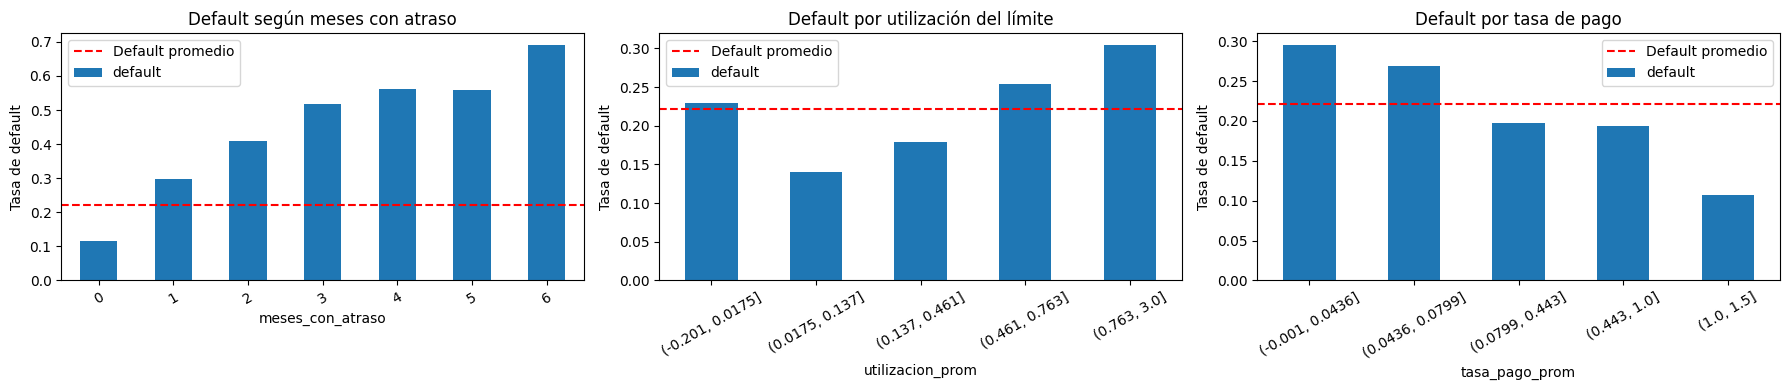

In [ ]:
# Relación de variables construidas con el default
aux = preview.assign(default=y_train)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Meses con atraso
aux.groupby("meses_con_atraso")["default"].mean().plot(
    kind="bar", ax=axes[0], title="Default según meses con atraso"
)

# Utilización promedio
aux.groupby(
    pd.qcut(aux["utilizacion_prom"], 5, duplicates="drop"),
    observed=True
)["default"].mean().plot(
    kind="bar", ax=axes[1], title="Default por utilización del límite"
)

# Tasa de pago promedio
aux.groupby(
    pd.qcut(aux["tasa_pago_prom"], 5, duplicates="drop"),
    observed=True
)["default"].mean().plot(
    kind="bar", ax=axes[2], title="Default por tasa de pago"
)

for ax in axes:
    ax.axhline(
        y_train.mean(),
        color="red",
        linestyle="--",
        label="Default promedio"
    )
    ax.set_ylabel("Tasa de default")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()

plt.tight_layout()
plt.show()

Los predictores construidos muestran una relación consistente con el default. La tasa de incumplimiento aumenta claramente con la cantidad de meses con atraso y tiende a ser mayor ante niveles elevados de utilización del crédito. En sentido contrario, una mayor tasa de pago se asocia con una menor proporción de default. Estos resultados respaldan la incorporación de las variables derivadas al modelado.

# **Empaquetado**

Las transformaciones se integran en un único Pipeline.
Los parámetros del preprocesamiento se ajustan exclusivamente sobre el conjunto de entrenamiento y luego se aplican, sin reajuste, a los conjuntos de evaluación y producción. Esto garantiza un tratamiento consistente de los datos y evita filtraciones de información.(data leak)

In [ ]:
# Variables según tipo
FEATURES = {
    "categoricas": [
        "education",
        "marriage"
    ] + (["sex"] if INCLUIR_SEXO else []),

    "numericas": (
        [
            "age",
            "log_limit_bal",
            "max_atraso",
            "meses_con_atraso",
            "utilizacion_1",
            "utilizacion_prom",
            "tasa_pago_prom",
            "tendencia_deuda"
        ]
        + COLS_PAY
        + [f"log_{c}" for c in COLS_BILL + COLS_PAY_AMT]
    )
}


def construir_transformaciones():

    # Numéricas: imputación + escalado
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categóricas: imputación + one-hot encoding
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    # Transformaciones según tipo de variable
    columnas = ColumnTransformer(
        [
            ("numericas", num_pipe, FEATURES["numericas"]),
            ("categoricas", cat_pipe, FEATURES["categoricas"])
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    # Pipeline completo
    transformaciones = Pipeline([
        ("preprocess", FunctionTransformer(preprocess)),
        ("columnas", columnas)
    ])

    transformaciones.set_output(transform="pandas")

    return transformaciones

Ajustamos las transformaciones **sólo con entrenamiento** y las aplicamos a evaluación y producción:

In [ ]:
# Construimos el pipeline de transformaciones
transformaciones = construir_transformaciones()

# Se aprende el preprocesamiento únicamente con entrenamiento
X_train_prep = transformaciones.fit_transform(X_train)

# En evaluación y producción solo se aplican las transformaciones aprendidas
X_test_prep = transformaciones.transform(X_test)
X_prod_prep = transformaciones.transform(X_prod)

# Controles
print("Predictores finales:", X_train_prep.shape[1])
print("Faltantes:", X_train_prep.isna().sum().sum())

assert X_train_prep.isna().sum().sum() == 0
assert list(X_train_prep.columns) == list(X_test_prep.columns)
assert list(X_train_prep.columns) == list(X_prod_prep.columns)

X_train_prep.head()

Predictores finales: 33
Faltantes: 0


,age,log_limit_bal,max_atraso,meses_con_atraso,utilizacion_1,utilizacion_prom,tasa_pago_prom,tendencia_deuda,pay_1,pay_2,...,log_pay_amt4,log_pay_amt5,log_pay_amt6,education_graduate school,education_high school,education_others,education_university,marriage_married,marriage_other,marriage_single
3336,-1.246132,-0.890504,1.213907,0.104622,1.307922,1.249429,-0.877876,0.905904,-0.468136,-0.398926,...,0.244661,0.361520,0.281136,0.0,0.0,0.0,1.0,0.0,0.0,1.0
14434,-0.811870,0.201576,-0.636047,-0.538454,-1.030382,-1.001666,1.441366,-0.365230,-0.468136,-0.398926,...,0.701549,0.289606,0.487327,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3233,-0.269043,0.579890,0.288930,0.104622,-1.041521,-1.067720,1.440418,-0.353611,0.826529,-0.398926,...,-1.791943,-1.752909,-1.686335,0.0,0.0,0.0,1.0,1.0,0.0,0.0
9945,-1.246132,0.936777,-0.636047,-0.538454,-1.028613,-1.036041,1.445297,-0.335969,-0.468136,-0.398926,...,-1.791943,-1.752909,-1.686335,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6164,-0.269043,1.551776,0.288930,0.104622,-1.027333,-0.907298,0.968086,-0.893350,0.826529,-0.398926,...,1.545537,0.572804,0.705552,1.0,0.0,0.0,0.0,1.0,0.0,0.0


##3. Modelado

## esta es una nueva prueba